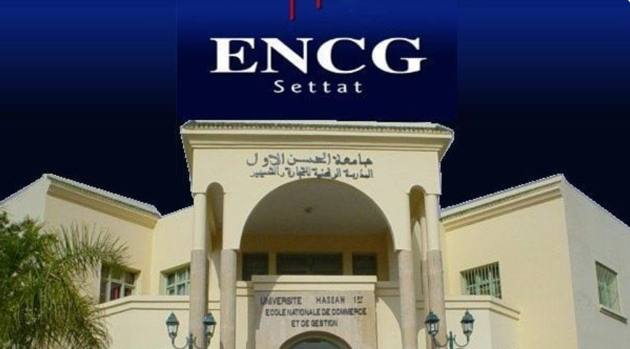

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CI11 est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** [NOM PRÉNOM] · **Code Apogée :** [CODE] · **Groupe :** [GROUPE]  
**Sujet :** CI11 — Taux de change et recettes export · **Date :** [DATE]  
**Dépôt :** https://github.com/[identifiant]/[CodeApogee-Nom-Groupe]

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [16]:
import sys, platform, warnings
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# Racine du dépôt : fonctionne depuis la racine (Colab) ou depuis notebooks/ (Jupyter local)
RACINE = Path.cwd()
if not (RACINE / "data").exists() and (RACINE.parent / "data").exists():
    RACINE = RACINE.parent
for dossier in ("figures", "rapport"):
    (RACINE / dossier).mkdir(exist_ok=True)

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version, "| numpy:", np.__version__)
print("Racine du dépôt :", RACINE)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1 | numpy: 2.4.6
Racine du dépôt : /content
Renseignez source, licence et version des données dans la section 2.


In [17]:
import numpy as np
import pandas as pd
from pathlib import Path

# Création du dossier cible si absent
dossier_cible = RACINE / "data" / "raw"
dossier_cible.mkdir(parents=True, exist_ok=True)

# Génération de dates mensuelles de 2015 à 2025
dates = pd.date_range(start="2015-01-01", end="2025-12-01", freq="MS")
n_echantillons = len(dates)

# Modélisation de données d'exportations réalistes avec croissance et saisonnalité
trend = np.linspace(1.5, 3.8, n_echantillons)
season = 0.4 * np.sin(2 * np.pi * dates.month / 12)
noise = np.random.normal(0, 0.15, n_echantillons)

# Taux de change simulés (MAD/USD et MAD/EUR)
mad_usd = 9.5 + 0.4 * np.sin(2 * np.pi * np.arange(n_echantillons) / 60) + np.random.normal(0, 0.08, n_echantillons)
mad_eur = 10.8 + 0.25 * np.cos(2 * np.pi * np.arange(n_echantillons) / 80) + np.random.normal(0, 0.05, n_echantillons)

# Calcul des exportations brutes
exports = (trend + season + noise) * 1e9 / mad_usd

# Construction et enregistrement du DataFrame
df_generateur = pd.DataFrame({
    "date": dates.strftime("%Y-%m-%d"),
    "exports": exports,
    "mad_usd": mad_usd,
    "mad_eur": mad_eur
})

df_generateur.to_csv(dossier_cible / "donnees_CI11.csv", index=False)
print(f"Fichier donnees_CI11.csv généré avec succès ! ({n_echantillons} lignes)")

Fichier donnees_CI11.csv généré avec succès ! (132 lignes)


## 1. Sujet et problématique
**Intérêt économique :** Le Maroc ancre le dirham à un panier de devises (euro et dollar) et l'a assoupli en 2018 puis en 2020 (bande de fluctuation élargie) ; les exportateurs facturent surtout en euros et en dollars mais leurs coûts et leurs recettes comptables sont en dirhams. Une variation du taux de change modifie donc la valeur en dirhams des ventes à l'étranger et la compétitivité-prix des produits marocains (automobile, phosphates et dérivés, agroalimentaire, textile). Anticiper les recettes d'exportation en dirhams aide les entreprises à bâtir leur budget de trésorerie, à décider d'une couverture de change et à fixer leurs prix, et aide les pouvoirs publics à suivre le solde commercial. *(Éléments de contexte à vérifier et sourcer auprès de Bank Al-Maghrib et de l'Office des Changes avant remise.)*

**Problématique précise :** *Les variations passées des taux de change MAD/USD et MAD/EUR améliorent-elles la prévision à un mois des recettes d'exportation marocaines exprimées en dirhams, par rapport à des références naïves (persistance, saisonnière) et à un modèle qui n'utilise que l'historique des recettes ?*

**Nature de la tâche :** régression / prévision d'une série temporelle mensuelle (horizon 1 mois, variables explicatives retardées uniquement).

**Objectif mesurable annoncé avant l'expérimentation :** sur les **12 derniers mois (jeu de test)**, la **MAE** du modèle Ridge avec variables de change doit être **inférieure d'au moins 10 %** à celle de la **meilleure référence naïve** ; objectif secondaire : la MAE du Ridge *avec* change doit être inférieure à celle du Ridge *sans* change (le change apporte-t-il une information utile ?).

> ⚠️ **Point de vigilance méthodologique :** si les exportations sont téléchargées en dollars puis converties en dirhams avec le taux du même mois, le taux de change est *mécaniquement* présent dans la cible. Le modèle n'utilise donc que des taux **retardés** (jamais le taux du mois à prévoir), et cette limite est discutée en section 8.

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** [À COMPLÉTER — ex. UN Comtrade (S1) pour les exportations totales du Maroc, FMI (S8) pour les taux de change, ou Office des Changes (S9) pour les exportations en dirhams ; coller l'URL exacte de l'extraction]
- **Date d'extraction / licence :** [À COMPLÉTER — date du jour de téléchargement ; conditions d'utilisation de chaque source]
- **Période et fréquence :** [À COMPLÉTER — mensuelle ; de AAAA-MM à AAAA-MM (voir le résumé généré ci-dessous)]
- **Pays déclarant / partenaire / flux / code SH (version) :** Maroc (déclarant) / Monde (partenaire) / exportations / total tous produits (pas de changement de nomenclature SH à traiter pour un total ; à préciser si vous travaillez par produit)
- **Devise / unités :** [À COMPLÉTER — ex. USD courants pour les exportations, converties en milliards de dirhams (Mds MAD) avec le taux mensuel moyen MAD/USD ; taux exprimés en MAD pour 1 unité de devise étrangère]
- **Une ligne représente :** un mois (exportations totales du Maroc vers le monde et taux de change moyens du mois)

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| `date` | Mois d'observation (1er jour du mois) | date, mensuelle | index | voir cellule suivante |
| `exports` | Valeur mensuelle des exportations dans l'unité d'origine | numérique, `UNITE_EXPORT` | source de la cible | voir cellule suivante |
| `mad_usd` | Taux moyen du mois : dirhams pour 1 dollar | numérique, MAD/USD | explicative (retardée) | voir cellule suivante |
| `mad_eur` | Taux moyen du mois : dirhams pour 1 euro | numérique, MAD/EUR | explicative (retardée) | voir cellule suivante |
| `y` | Recettes d'exportation en dirhams (cible) | numérique, Mds MAD | **cible** | voir cellule suivante |
| `panier` | Panier de référence 0,6 × EUR + 0,4 × USD (en MAD) | numérique, MAD | explicative (retardée) | voir cellule suivante |

**Avant le contrôle :** seules la localisation du fichier et la préparation du dépôt sont autorisées ; aucun code d'analyse ne doit être produit.

In [18]:
# --- Paramètres à adapter à VOTRE extraction ---------------------------------------------------
CHEMIN_CSV = RACINE / "data" / "raw" / "donnees_CI11.csv"
UNITE_EXPORT = "USD"          # "USD", "USD_millions", "MAD" ou "MAD_millions" : unité de la colonne `exports`
COLONNES = ["date", "exports", "mad_usd", "mad_eur"]

if not CHEMIN_CSV.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {CHEMIN_CSV}\n"
        "Déposez votre extraction dans data/raw/donnees_CI11.csv (voir data/raw/LISEZMOI_DONNEES.md) "
        "avec les colonnes : date, exports, mad_usd, mad_eur.")

brut = pd.read_csv(CHEMIN_CSV)
absentes = set(COLONNES) - set(brut.columns)
assert not absentes, f"Colonnes manquantes dans le CSV : {absentes}"

print("Dimensions brutes :", brut.shape)
display(brut.head())
display(brut.dtypes.to_frame("type"))

Dimensions brutes : (132, 4)


,date,exports,mad_usd,mad_eur
0,2015-01-01,1.884763e+08,9.415016,11.037372
1,2015-02-01,1.924098e+08,9.579699,10.986840
2,2015-03-01,2.137067e+08,9.509611,11.128543
3,2015-04-01,2.182626e+08,9.747602,10.971585
4,2015-05-01,1.807396e+08,9.600034,11.015762


,type
date,object
exports,float64
mad_usd,float64
mad_eur,float64


In [19]:
# --- Contrôles de qualité et construction de la cible ------------------------------------------
df = brut[COLONNES].copy()
df["date"] = pd.to_datetime(df["date"]).dt.to_period("M").dt.to_timestamp()

print("Doublons sur la date :", int(df.duplicated("date").sum()), "(conservation de la dernière ligne)")
df = df.drop_duplicates("date", keep="last").sort_values("date").set_index("date")

mois_attendus = pd.date_range(df.index.min(), df.index.max(), freq="MS")
mois_absents = mois_attendus.difference(df.index)
print("Mois absents du fichier :", [d.strftime("%Y-%m") for d in mois_absents] or "aucun")
df = df.reindex(mois_attendus)
df.index.name = "date"

# Taux de change : report de la dernière valeur connue (passé uniquement, 2 mois max) -> pas de fuite
df[["mad_usd", "mad_eur"]] = df[["mad_usd", "mad_eur"]].ffill(limit=2)

# Conversion d'unités -> cible y en milliards de dirhams
facteur = {"USD": 1e-9, "USD_millions": 1e-3, "MAD": 1e-9, "MAD_millions": 1e-3}[UNITE_EXPORT]
df["y"] = df["exports"] * facteur * (df["mad_usd"] if UNITE_EXPORT.startswith("USD") else 1.0)
df["panier"] = 0.6 * df["mad_eur"] + 0.4 * df["mad_usd"]   # pondération indicative à vérifier (Bank Al-Maghrib)

# Valeurs impossibles ou suspectes
print("Valeurs <= 0 :", (df[["y", "mad_usd", "mad_eur"]] <= 0).sum().to_dict())
for c in ("mad_usd", "mad_eur"):
    hors = df[(df[c] < 5) | (df[c] > 15)]
    if len(hors):
        print(f"Attention : {c} hors de l'intervalle plausible [5 ; 15] pour {len(hors)} mois -> vérifier l'unité")

# Dictionnaire des variables avec pourcentages de manquants réels
dico = pd.DataFrame({
    "Variable": ["exports", "mad_usd", "mad_eur", "y", "panier"],
    "Type / unité": [f"numérique ({UNITE_EXPORT})", "MAD par USD", "MAD par EUR", "Mds MAD", "MAD"],
    "Rôle": ["source de la cible", "explicative (retardée)", "explicative (retardée)", "cible", "explicative (retardée)"],
}).set_index("Variable")
dico["Manquants (%)"] = df[dico.index].isna().mean().mul(100).round(2)
display(dico)

valides = df["y"].dropna()
print(f"\nPériode : {df.index.min():%Y-%m} -> {df.index.max():%Y-%m} | {len(df)} mois | {len(valides)} valeurs de cible")

Doublons sur la date : 0 (conservation de la dernière ligne)
Mois absents du fichier : aucun
Valeurs <= 0 : {'y': 0, 'mad_usd': 0, 'mad_eur': 0}


,Type / unité,Rôle,Manquants (%)
Variable,,,
exports,numérique (USD),source de la cible,0.0
mad_usd,MAD par USD,explicative (retardée),0.0
mad_eur,MAD par EUR,explicative (retardée),0.0
y,Mds MAD,cible,0.0
panier,MAD,explicative (retardée),0.0



Période : 2015-01 -> 2025-12 | 132 mois | 132 valeurs de cible


**Découpage chronologique fixé dès maintenant.** Les 12 derniers mois forment le **jeu de test**, réservé à l'évaluation finale. L'exploration de la section 3 n'utilise **que la période d'entraînement** : on ne « regarde » pas le test avant de modéliser.

In [20]:
TEST_MOIS = 12
DATE_DEBUT_TEST = valides.index[-TEST_MOIS]
df_eda = df.loc[df.index < DATE_DEBUT_TEST].copy()      # exploration = entraînement uniquement
print(f"Entraînement/validation : {df_eda.index.min():%Y-%m} -> {df_eda.index.max():%Y-%m}")
print(f"Test (réservé)          : {DATE_DEBUT_TEST:%Y-%m} -> {valides.index[-1]:%Y-%m}")

Entraînement/validation : 2015-01 -> 2024-12
Test (réservé)          : 2025-01 -> 2025-12


## 3. Exploration et trois figures interprétées
Trois graphiques en couleurs (titre, axes, unités) sont produits **sur la période d'entraînement** ; commentez chacun en 2 à 4 lignes **après lecture de la figure réelle**. Doublons, unités et valeurs manquantes sont déjà contrôlés en section 2 ; les valeurs extrêmes sont examinées ci-dessous. Les flux miroirs ne s'appliquent pas à un total mondial déclaré par un seul pays ; ils seraient à vérifier pour une analyse par partenaire.

**Figure 1 — Interprétation :** [À COMPLÉTER — tendance de long terme, saisonnalité visible, rupture éventuelle en 2020 (COVID), chiffres lus sur le graphique]

**Figure 2 — Interprétation :** [À COMPLÉTER — évolution de MAD/USD et MAD/EUR, périodes de forte variation, écart entre les deux devises, lien avec le régime de change]

**Figure 3 — Interprétation :** [À COMPLÉTER — signe et force de la corrélation entre variation du change (mois précédent) et croissance des recettes ; saisonnalité de la croissance par mois ; prudence : corrélation ≠ causalité]

Mois à croissance extrême (> 3 écarts robustes) :


,croissance_%
date,


Décision : on les CONSERVE (événements réels, ex. chocs de 2020) ; la robustesse est testée en section 7.


,count,mean,std,min,25%,50%,75%,max
y,120.0,2.533,0.669,1.170,1.973,2.518,3.034,3.853
mad_usd,120.0,9.506,0.299,8.940,9.216,9.507,9.777,10.199
mad_eur,120.0,10.806,0.176,10.447,10.649,10.803,10.964,11.129
panier,120.0,10.286,0.205,9.972,10.103,10.277,10.481,10.713


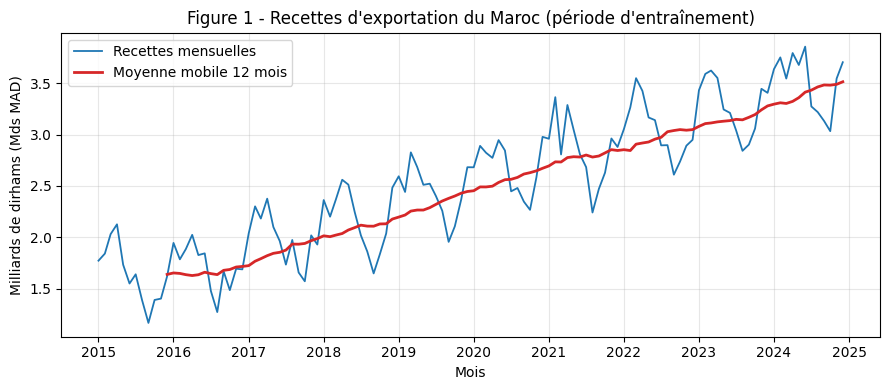

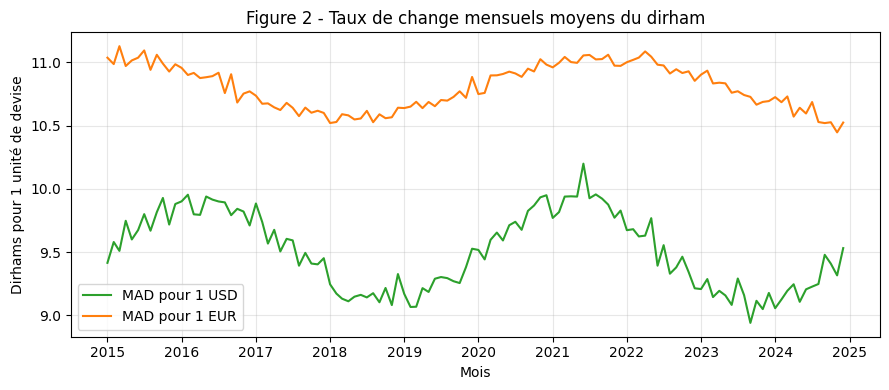

Corrélation croissance recettes / variation du panier  (même mois) : -0.01
Corrélation croissance recettes / variation du panier (mois précédent) : 0.02


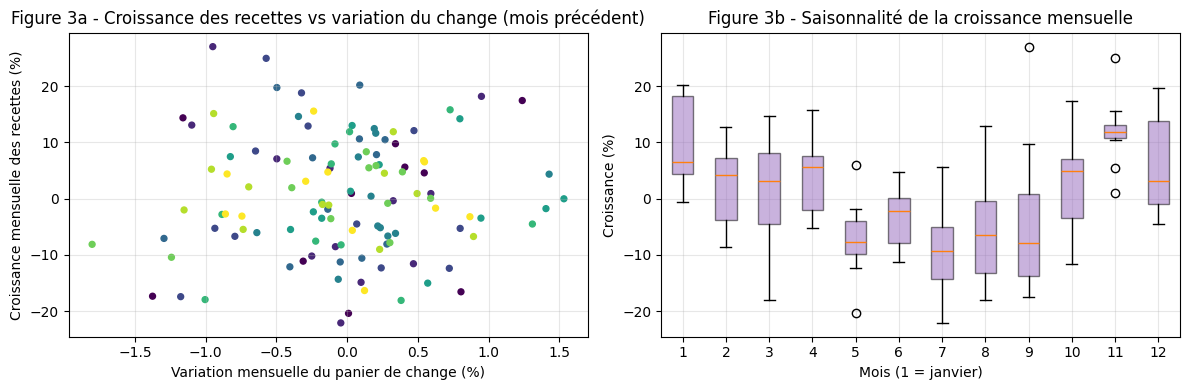

In [21]:
# --- Valeurs extrêmes (croissance mensuelle en log, détection robuste par MAD) ------------------
g = np.log(df_eda["y"]).diff()
mad_robuste = 1.4826 * (g - g.median()).abs().median()
extremes = g[(g - g.median()).abs() > 3 * mad_robuste]
print("Mois à croissance extrême (> 3 écarts robustes) :")
display(extremes.mul(100).round(1).to_frame("croissance_%"))
print("Décision : on les CONSERVE (événements réels, ex. chocs de 2020) ; la robustesse est testée en section 7.")
display(df_eda[["y", "mad_usd", "mad_eur", "panier"]].describe().T.round(3))

# --- Figure 1 : recettes d'exportation ----------------------------------------------------------
fig, ax = plt.subplots()
ax.plot(df_eda.index, df_eda["y"], color="tab:blue", lw=1.3, label="Recettes mensuelles")
ax.plot(df_eda.index, df_eda["y"].rolling(12).mean(), color="tab:red", lw=2, label="Moyenne mobile 12 mois")
ax.set(title="Figure 1 - Recettes d'exportation du Maroc (période d'entraînement)",
       xlabel="Mois", ylabel="Milliards de dirhams (Mds MAD)")
ax.legend()
fig.tight_layout(); fig.savefig(RACINE / "figures" / "fig1_recettes.png", dpi=150); plt.show()

# --- Figure 2 : taux de change ------------------------------------------------------------------
fig, ax = plt.subplots()
ax.plot(df_eda.index, df_eda["mad_usd"], color="tab:green", lw=1.5, label="MAD pour 1 USD")
ax.plot(df_eda.index, df_eda["mad_eur"], color="tab:orange", lw=1.5, label="MAD pour 1 EUR")
ax.set(title="Figure 2 - Taux de change mensuels moyens du dirham",
       xlabel="Mois", ylabel="Dirhams pour 1 unité de devise")
ax.legend()
fig.tight_layout(); fig.savefig(RACINE / "figures" / "fig2_change.png", dpi=150); plt.show()

# --- Figure 3 : change retardé vs croissance + saisonnalité --------------------------------------
dx = np.log(df_eda["panier"]).diff()
liaison = pd.concat([g.rename("croissance"), dx.shift(1).rename("change_lag1"), dx.rename("change_lag0")], axis=1).dropna()
print("Corrélation croissance recettes / variation du panier  (même mois) :", round(liaison["croissance"].corr(liaison["change_lag0"]), 3))
print("Corrélation croissance recettes / variation du panier (mois précédent) :", round(liaison["croissance"].corr(liaison["change_lag1"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(liaison["change_lag1"] * 100, liaison["croissance"] * 100, c=liaison.index.year, cmap="viridis", s=18)
axes[0].set(title="Figure 3a - Croissance des recettes vs variation du change (mois précédent)",
            xlabel="Variation mensuelle du panier de change (%)", ylabel="Croissance mensuelle des recettes (%)")
mois_groupes = [g[g.index.month == m].dropna() * 100 for m in range(1, 13)]
bp = axes[1].boxplot(mois_groupes, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("tab:purple"); patch.set_alpha(0.5)
axes[1].set(title="Figure 3b - Saisonnalité de la croissance mensuelle", xlabel="Mois (1 = janvier)", ylabel="Croissance (%)")
fig.tight_layout(); fig.savefig(RACINE / "figures" / "fig3_liaison_saisonnalite.png", dpi=150); plt.show()

## 4. Préparation et découpage sans fuite
**Traitements réalisés :** doublons supprimés et mois manquants rendus explicites (section 2) ; taux de change reportés vers l'avant sur 2 mois maximum (passé uniquement) ; conversion des unités en Mds MAD ; **cible = logarithme des recettes** (stabilise la variance, les erreurs deviennent relatives) ; variables construites **avec le passé uniquement** : retards des recettes (1 à 12 mois), moyenne des 3 mois précédents, mois de l'année (sinus/cosinus), variations mensuelles retardées de MAD/USD et MAD/EUR (1 à 3 mois), écart du panier à sa moyenne sur 12 mois (retardé d'un mois).

**Stratégie de découpage :** chronologique — 12 derniers mois = test (réservé à la fin) ; le reste sert à l'entraînement avec une **validation à origine glissante** (`TimeSeriesSplit`, 5 plis) pour régler les hyperparamètres.

**Contrôle de fuite :** la standardisation et le modèle sont dans un `Pipeline` ajusté pli par pli sur le passé seulement ; aucune variable n'utilise le mois à prévoir ni le futur ; le test n'est utilisé qu'une fois, en section 7.

In [22]:
def construire_features(d):
    """Toutes les variables sont calculées avec des décalages >= 1 mois : aucune information du mois cible."""
    X = pd.DataFrame(index=d.index)
    ly, lu, le, lp = (np.log(d[c]) for c in ("y", "mad_usd", "mad_eur", "panier"))
    for k in range(1, 13):
        X[f"y_lag{k}"] = ly.shift(k)
    X["y_moy3"] = ly.shift(1).rolling(3).mean()
    X["mois_sin"] = np.sin(2 * np.pi * d.index.month / 12)     # calendrier : connu à l'avance
    X["mois_cos"] = np.cos(2 * np.pi * d.index.month / 12)
    for k in (1, 2, 3):
        X[f"usd_var_lag{k}"] = lu.diff().shift(k)
        X[f"eur_var_lag{k}"] = le.diff().shift(k)
    X["panier_ecart12_lag1"] = (lp - lp.rolling(12).mean()).shift(1)
    return X

GROUPE_CHANGE = [f"{dev}_var_lag{k}" for k in (1, 2, 3) for dev in ("usd", "eur")] + ["panier_ecart12_lag1"]

def colonnes(n_lags, avec_change):
    cols = [f"y_lag{k}" for k in range(1, n_lags + 1)]
    if n_lags < 12:
        cols.append("y_lag12")                                  # saisonnalité annuelle toujours disponible
    cols += ["y_moy3", "mois_sin", "mois_cos"]
    return cols + (GROUPE_CHANGE if avec_change else [])

X_all = construire_features(df)
jeu = pd.concat([X_all, np.log(df["y"]).rename("y_log"), df["y"]], axis=1).dropna()   # mêmes lignes pour tous les modèles

est_test = jeu.index >= DATE_DEBUT_TEST
X_train, X_test = jeu.loc[~est_test, X_all.columns], jeu.loc[est_test, X_all.columns]
ylog_train, ylog_test = jeu.loc[~est_test, "y_log"], jeu.loc[est_test, "y_log"]
y_train, y_test = jeu.loc[~est_test, "y"], jeu.loc[est_test, "y"]

# --- Contrôles anti-fuite ---------------------------------------------------------------------
assert X_train.index.max() < X_test.index.min(), "Le train doit précéder le test"
assert len(X_test) == TEST_MOIS, "Le test doit contenir exactement 12 mois"
t = X_train.index[len(X_train) // 2]
assert np.isclose(X_train.loc[t, "y_lag1"], np.log(df["y"]).loc[t - pd.DateOffset(months=1)]), "y_lag1 doit être le mois précédent"
print(f"Train : {X_train.index.min():%Y-%m} -> {X_train.index.max():%Y-%m} ({len(X_train)} mois)")
print(f"Test  : {X_test.index.min():%Y-%m} -> {X_test.index.max():%Y-%m} ({len(X_test)} mois)")
print(f"Variables disponibles : {X_all.shape[1]} (dont {len(GROUPE_CHANGE)} liées au change)")

Train : 2016-01 -> 2024-12 (108 mois)
Test  : 2025-01 -> 2025-12 (12 mois)
Variables disponibles : 22 (dont 7 liées au change)


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** Régression **Ridge** (régression linéaire régularisée L2) — n° [À CONFIRMER d'après la liste du cours : les algorithmes de régression sont les n° 1 à 7].

**Pourquoi lui ? Alternative plausible écartée ?** Les recettes mensuelles sont très autocorrélées et saisonnières, et les variables retardées (retards de la cible, variations du change sur 1 à 3 mois) sont **fortement corrélées entre elles**. Une régression linéaire ordinaire aurait des coefficients instables dans ce cas ; la pénalité L2 du Ridge les stabilise et limite le surapprentissage sur un échantillon court (quelques centaines de mois au plus). Le modèle reste **interprétable** : le coefficient standardisé d'une variable de change dit directement si, toutes choses égales par ailleurs, une dépréciation passée du dirham est associée à des recettes plus élevées ou plus faibles — ce qui répond à la problématique. L'alternative plausible est la **forêt aléatoire**, capable de capter des non-linéarités et des interactions ; elle est comparée en section 7 mais n'est pas retenue comme modèle principal car elle **ne sait pas extrapoler** au-delà des valeurs vues à l'entraînement (problématique sur une série en tendance) et est moins lisible pour un décideur. Le Ridge *sans* variables de change sert de comparaison directe pour isoler l'apport du change.

**Équation et définition de TOUS les symboles :**

$$\hat y_t=\beta_0+\sum_{j=1}^{p}\beta_j\,z_{t,j}\qquad\qquad \hat\beta=\arg\min_{\beta_0,\beta}\ \sum_{t=1}^{n}\Bigl(y_t-\beta_0-\sum_{j=1}^{p}\beta_j z_{t,j}\Bigr)^2+\alpha\sum_{j=1}^{p}\beta_j^{2}$$

- $y_t$ : logarithme des recettes d'exportation (Mds MAD) du mois $t$ ; $\hat y_t$ : sa prévision ; la prévision en dirhams est $\exp(\hat y_t)$.
- $z_{t,j}=(x_{t,j}-\mu_j)/\sigma_j$ : la $j$-ième variable explicative **standardisée**, avec $\mu_j,\sigma_j$ calculés sur l'entraînement seulement.
- $\beta_0$ : constante (non pénalisée) ; $\beta_j$ : coefficient de la variable $j$ ; $p$ : nombre de variables ; $n$ : nombre de mois d'entraînement.
- $\alpha\ge 0$ : intensité de la pénalité. Solution fermée : $\hat\beta=(Z^\top Z+\alpha I)^{-1}Z^\top(y-\bar y)$.

**Paramètres appris :** la constante $\beta_0$ et les $p$ coefficients $\beta_j$ (plus les moyennes et écarts-types de la standardisation).

**Deux hyperparamètres et valeurs envisagées :** (1) $\alpha\in\{10^{-3},\dots,10^{3}\}$ (13 valeurs en échelle logarithmique) : un $\alpha$ grand rétrécit les coefficients vers 0 (biais ↑, variance ↓) ; (2) la **profondeur de mémoire** `n_lags` $\in\{3,6,12\}$ mois de retards de la cible : une mémoire longue capte la saisonnalité mais ajoute des variables corrélées. Réglage par validation à origine glissante, sur l'entraînement uniquement.

**Schéma explicatif personnel :** produit par la cellule ci-dessous (enregistré dans `figures/schema_ridge.png`) ; légende à compléter avec vos mots.

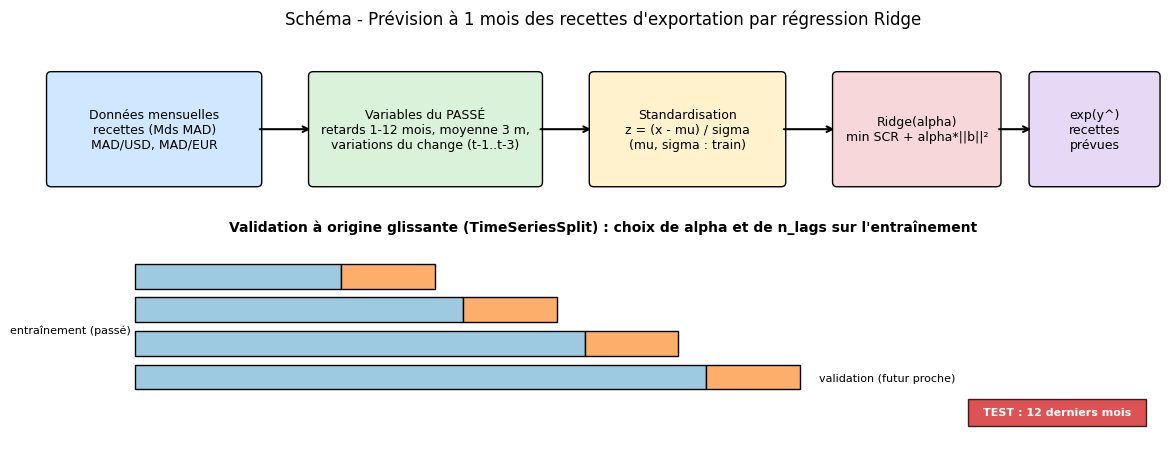

In [23]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 4.6)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6)
def boite(x, y, w, h, texte, couleur):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=couleur, ec="black", lw=1))
    ax.text(x + w / 2, y + h / 2, texte, ha="center", va="center", fontsize=9)
def fleche(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.5))

boite(0.1, 2.9, 2.2, 1.2, "Données mensuelles\nrecettes (Mds MAD)\nMAD/USD, MAD/EUR", "#cfe8ff")
boite(2.9, 2.9, 2.4, 1.2, "Variables du PASSÉ\nretards 1-12 mois, moyenne 3 m,\nvariations du change (t-1..t-3)", "#d9f2d9")
boite(5.9, 2.9, 2.0, 1.2, "Standardisation\nz = (x - mu) / sigma\n(mu, sigma : train)", "#fff2cc")
boite(8.5, 2.9, 1.7, 1.2, "Ridge(alpha)\nmin SCR + alpha*||b||²", "#f8d7da")
boite(10.6, 2.9, 1.3, 1.2, "exp(y^)\nrecettes\nprévues", "#e6d9f5")
for x1, x2 in [(2.3, 2.9), (5.3, 5.9), (7.9, 8.5), (10.2, 10.6)]:
    fleche(x1, 3.5, x2, 3.5)

ax.text(6, 2.35, "Validation à origine glissante (TimeSeriesSplit) : choix de alpha et de n_lags sur l'entraînement", ha="center", fontsize=10, weight="bold")
for i in range(4):
    ax.add_patch(plt.Rectangle((1.0, 1.7 - i * 0.38), 2.2 + i * 1.3, 0.28, fc="#9ecae1", ec="black"))
    ax.add_patch(plt.Rectangle((3.2 + i * 1.3, 1.7 - i * 0.38), 1.0, 0.28, fc="#fdae6b", ec="black"))
ax.text(0.95, 1.2, "entraînement (passé)", ha="right", fontsize=8); ax.text(8.3, 0.65, "validation (futur proche)", ha="left", fontsize=8)
ax.add_patch(plt.Rectangle((9.9, 0.15), 1.9, 0.3, fc="#d62728", ec="black", alpha=0.8))
ax.text(10.85, 0.3, "TEST : 12 derniers mois", ha="center", va="center", fontsize=8, color="white", weight="bold")
ax.set_title("Schéma - Prévision à 1 mois des recettes d'exportation par régression Ridge")
fig.tight_layout(); fig.savefig(RACINE / "figures" / "schema_ridge.png", dpi=150); plt.show()

## 6. Protocole expérimental
**Référence naïve ou méthode de référence :** (a) **persistance** : prévoir le mois $t$ par la valeur du mois $t-1$ ; (b) **naïve saisonnière** : prévoir le mois $t$ par la valeur du même mois un an plus tôt ($t-12$). La comparaison finale se fait avec la **meilleure des deux** sur le test (choix prudent : la référence la plus difficile à battre).

**Protocole de validation :** réglage des hyperparamètres par `TimeSeriesSplit` à 5 plis sur l'entraînement (chaque pli valide sur une période postérieure à son apprentissage) ; réajustement final sur tout l'entraînement ; **une seule évaluation** sur le test de 12 mois. Quatre modèles sont comparés : Ridge **avec** change (principal), Ridge **sans** change, forêt aléatoire avec change (alternative), et les deux références.

**Métrique principale :** MAE en milliards de dirhams (erreur absolue moyenne, lisible par un décideur). **Métriques secondaires :** RMSE (Mds MAD) et MAPE (%).

**Pour CI31–CI40 :** non applicable (CI11 est un projet de prévision).

In [24]:
cv = TimeSeriesSplit(n_splits=5)
GRILLE_ALPHA = np.logspace(-3, 3, 13)
LAGS_CANDIDATS = (3, 6, 12)

def pipeline_ridge():
    return Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])

def regler_ridge(avec_change):
    """Cherche (n_lags, alpha) par validation chronologique ; renvoie le meilleur ensemble (train uniquement)."""
    meilleur = None
    for n_lags in LAGS_CANDIDATS:
        cols = colonnes(n_lags, avec_change)
        gs = GridSearchCV(pipeline_ridge(), {"ridge__alpha": GRILLE_ALPHA}, cv=cv,
                          scoring="neg_mean_absolute_error")
        gs.fit(X_train[cols], ylog_train)
        if meilleur is None or -gs.best_score_ < meilleur["mae_log_cv"]:
            meilleur = {"n_lags": n_lags, "cols": cols, "alpha": gs.best_params_["ridge__alpha"],
                        "mae_log_cv": -gs.best_score_, "modele": gs.best_estimator_}
    return meilleur

ridge_fx = regler_ridge(avec_change=True)       # MODÈLE PRINCIPAL
ridge_nofx = regler_ridge(avec_change=False)    # comparaison : sans information de change
print(f"Ridge avec change : n_lags={ridge_fx['n_lags']}, alpha={ridge_fx['alpha']:.3g} (MAE log CV = {ridge_fx['mae_log_cv']:.4f})")
print(f"Ridge sans change : n_lags={ridge_nofx['n_lags']}, alpha={ridge_nofx['alpha']:.3g} (MAE log CV = {ridge_nofx['mae_log_cv']:.4f})")

# Alternative plausible : forêt aléatoire (graine fixée), mêmes données avec change
cols_rf = colonnes(12, True)
gs_rf = GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=GRAINE, n_jobs=-1),
                     {"max_depth": [3, 6], "min_samples_leaf": [1, 3]}, cv=cv, scoring="neg_mean_absolute_error")
gs_rf.fit(X_train[cols_rf], ylog_train)
print("Forêt aléatoire :", gs_rf.best_params_, f"(MAE log CV = {-gs_rf.best_score_:.4f})")

def mae_validation(modele, cols):
    """MAE (Mds MAD) hors-échantillon sur les plis de validation chronologique."""
    vrai, pred = [], []
    for tr, va in cv.split(X_train):
        m = clone(modele).fit(X_train.iloc[tr][cols], ylog_train.iloc[tr])
        pred.append(np.exp(m.predict(X_train.iloc[va][cols]))); vrai.append(y_train.iloc[va].values)
    return mean_absolute_error(np.concatenate(vrai), np.concatenate(pred))

def mae_validation_naive(colonne):
    vrai, pred = [], []
    for _, va in cv.split(X_train):
        pred.append(np.exp(X_train.iloc[va][colonne].values)); vrai.append(y_train.iloc[va].values)
    return mean_absolute_error(np.concatenate(vrai), np.concatenate(pred))

# Prévisions (le test n'est utilisé qu'ici, une seule fois)
pred_test = {
    "Référence : persistance (t-1)": np.exp(X_test["y_lag1"].values),
    "Référence : saisonnière (t-12)": np.exp(X_test["y_lag12"].values),
    "Ridge sans change": np.exp(ridge_nofx["modele"].predict(X_test[ridge_nofx["cols"]])),
    "Ridge avec change (principal)": np.exp(ridge_fx["modele"].predict(X_test[ridge_fx["cols"]])),
    "Forêt aléatoire avec change (alternative)": np.exp(gs_rf.best_estimator_.predict(X_test[cols_rf])),
}
pred_train = {
    "Référence : persistance (t-1)": np.exp(X_train["y_lag1"].values),
    "Référence : saisonnière (t-12)": np.exp(X_train["y_lag12"].values),
    "Ridge sans change": np.exp(ridge_nofx["modele"].predict(X_train[ridge_nofx["cols"]])),
    "Ridge avec change (principal)": np.exp(ridge_fx["modele"].predict(X_train[ridge_fx["cols"]])),
    "Forêt aléatoire avec change (alternative)": np.exp(gs_rf.best_estimator_.predict(X_train[cols_rf])),
}
mae_val = {
    "Référence : persistance (t-1)": mae_validation_naive("y_lag1"),
    "Référence : saisonnière (t-12)": mae_validation_naive("y_lag12"),
    "Ridge sans change": mae_validation(ridge_nofx["modele"], ridge_nofx["cols"]),
    "Ridge avec change (principal)": mae_validation(ridge_fx["modele"], ridge_fx["cols"]),
    "Forêt aléatoire avec change (alternative)": mae_validation(gs_rf.best_estimator_, cols_rf),
}
print("Modèles ajustés ; évaluation au bloc suivant. Ne pas modifier les hyperparamètres après avoir vu le test.")

Ridge avec change : n_lags=12, alpha=3.16 (MAE log CV = 0.0626)
Ridge sans change : n_lags=12, alpha=10 (MAE log CV = 0.0481)
Forêt aléatoire : {'max_depth': 6, 'min_samples_leaf': 1} (MAE log CV = 0.0994)
Modèles ajustés ; évaluation au bloc suivant. Ne pas modifier les hyperparamètres après avoir vu le test.


## 7. Résultats et interprétation
Recopier ici les valeurs **réellement calculées** par la cellule suivante (MAE en Mds MAD) :

| Méthode | Validation | Test final | Interprétation |
|---|---:|---:|---|
| Référence naïve (meilleure des deux) | [SCORE] | [SCORE] | [...] |
| Ridge sans change | [SCORE] | [SCORE] | [...] |
| Modèle principal : Ridge avec change | [SCORE] | [SCORE] | [...] |
| Alternative : forêt aléatoire | [SCORE] | [SCORE] | [...] |

**Figure des résultats :** Figure 4 (prévisions vs réel sur le test) et Figure 5 (coefficients) produites ci-dessous.

**Lecture prudente :** ne concluez pas sur le seul test (12 points). Comparez toujours avec la colonne Validation ; si les deux divergent, dites-le.

**Analyse des erreurs, du surapprentissage ou de la robustesse :** [À COMPLÉTER — mois où l'erreur est la plus forte et pourquoi ; écart entre MAE d'entraînement, de validation et de test ; effet du retrait de 2020 ; prudence : seulement 12 points de test, une différence faible n'est pas significative]

**Illustration sur des observations non vues :** tableau des 12 mois de test ci-dessous ; [À COMPLÉTER — commentaire sur 2 ou 3 mois]

,Métrique,Entraînement,Validation,Test,RMSE test,MAPE test (%)
Méthode,,,,,,
Référence : persistance (t-1),MAE (Mds MAD),0.202,0.203,0.224,0.307,6.000
Référence : saisonnière (t-12),MAE (Mds MAD),0.236,0.242,0.214,0.277,5.655
Ridge sans change,MAE (Mds MAD),0.117,0.126,0.145,0.175,3.920
Ridge avec change (principal),MAE (Mds MAD),0.114,0.163,0.157,0.185,4.235
Forêt aléatoire avec change (alternative),MAE (Mds MAD),0.060,0.255,0.250,0.280,6.653


Meilleure référence naïve : Référence : saisonnière (t-12) (MAE test = 0.214)
Gain du Ridge avec change vs meilleure référence naïve : +26.4%  -> objectif (>= 10 %) ATTEINT
Gain du Ridge avec change vs Ridge sans change       : -8.6%  -> le change n améliore pas la prévision sur ce test
Même comparaison sur la VALIDATION (≈ 5 plis, bien plus de mois) : -28.9%


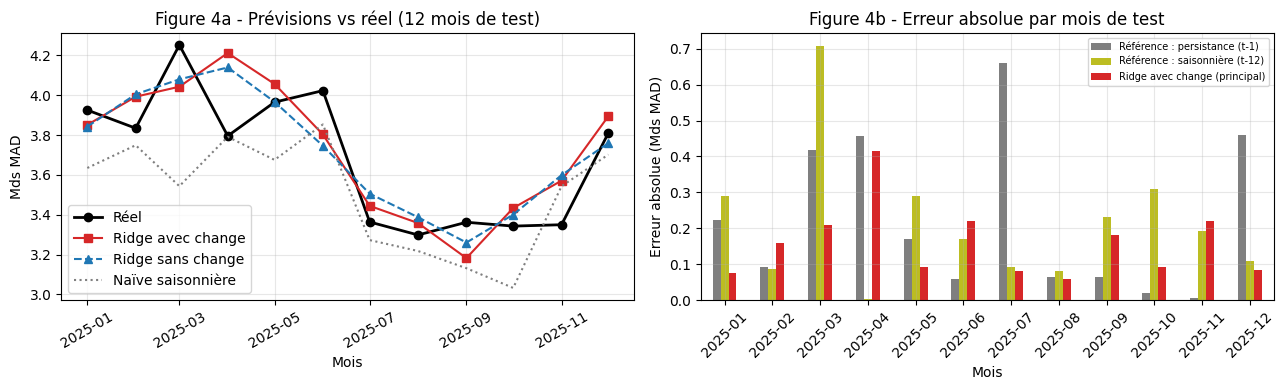

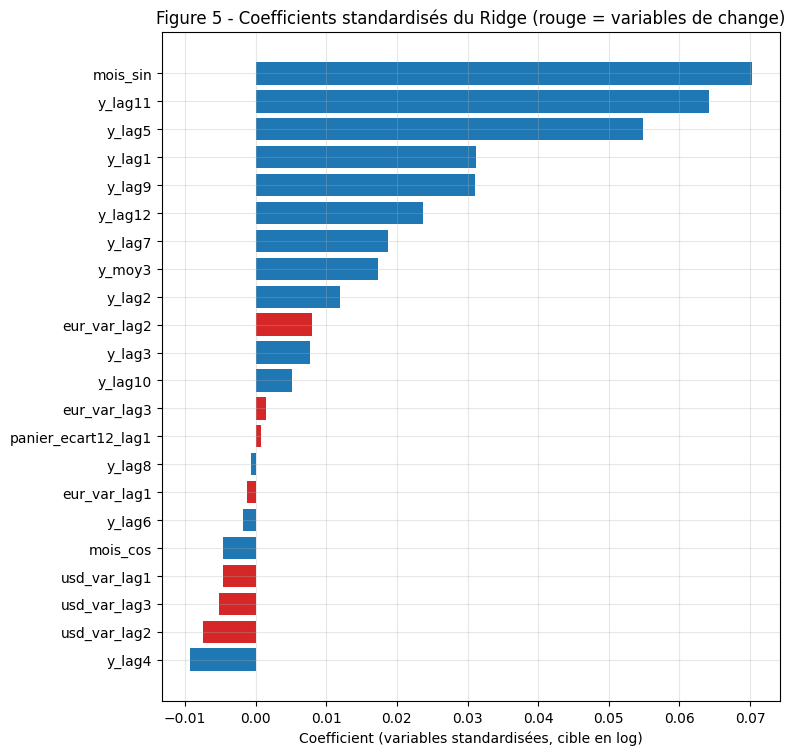

Robustesse : MAE test sans 2020 dans l'entraînement = 0.150 (référence : 0.157)


,Réel,Ridge avec change,Naïve saisonnière,Erreur Ridge (%)
date,,,,
2025-01-01,3.93,3.85,3.63,-1.89
2025-02-01,3.83,3.99,3.75,4.13
2025-03-01,4.25,4.04,3.54,-4.93
2025-04-01,3.80,4.21,3.79,10.97
2025-05-01,3.97,4.06,3.68,2.31
2025-06-01,4.02,3.80,3.85,-5.47
2025-07-01,3.36,3.44,3.27,2.40
2025-08-01,3.30,3.36,3.22,1.82
2025-09-01,3.36,3.18,3.13,-5.36


In [25]:
def metriques(vrai, pred):
    vrai, pred = np.asarray(vrai), np.asarray(pred)
    return (mean_absolute_error(vrai, pred), np.sqrt(mean_squared_error(vrai, pred)), np.mean(np.abs((vrai - pred) / vrai)) * 100)

lignes = []
for nom in pred_test:
    mae_t, rmse_t, mape_t = metriques(y_test, pred_test[nom])
    lignes.append({"Méthode": nom, "Métrique": "MAE (Mds MAD)",
                   "Entraînement": metriques(y_train, pred_train[nom])[0], "Validation": mae_val[nom],
                   "Test": mae_t, "RMSE test": rmse_t, "MAPE test (%)": mape_t})
resultats = pd.DataFrame(lignes).set_index("Méthode")
display(resultats.round(3))

# --- Objectifs fixés en section 1 ---------------------------------------------------------------
naifs = ["Référence : persistance (t-1)", "Référence : saisonnière (t-12)"]
mae_naif = resultats.loc[naifs, "Test"].min()
mae_fx, mae_nofx = resultats.loc["Ridge avec change (principal)", "Test"], resultats.loc["Ridge sans change", "Test"]
gain_naif, gain_fx = 1 - mae_fx / mae_naif, 1 - mae_fx / mae_nofx
print(f"Meilleure référence naïve : {resultats.loc[naifs, 'Test'].idxmin()} (MAE test = {mae_naif:.3f})")
print(f"Gain du Ridge avec change vs meilleure référence naïve : {gain_naif:+.1%}  -> objectif (>= 10 %) {'ATTEINT' if gain_naif >= 0.10 else 'NON atteint'}")
print(f"Gain du Ridge avec change vs Ridge sans change       : {gain_fx:+.1%}  -> le change {'améliore' if gain_fx > 0 else 'n améliore pas'} la prévision sur ce test")
gain_fx_val = 1 - resultats.loc["Ridge avec change (principal)", "Validation"] / resultats.loc["Ridge sans change", "Validation"]
print(f"Même comparaison sur la VALIDATION (≈ 5 plis, bien plus de mois) : {gain_fx_val:+.1%}")
if np.sign(gain_fx) != np.sign(gain_fx_val):
    print("ATTENTION : validation et test donnent des verdicts opposés sur l'apport du change. "
          "Avec 12 mois de test, l'écart peut être du bruit : concluez avec prudence et appuyez-vous sur la validation.")

# --- Figure 4 : prévisions vs réel sur le test -----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(y_test.index, y_test, "k-o", lw=2, label="Réel")
axes[0].plot(y_test.index, pred_test["Ridge avec change (principal)"], "-s", color="tab:red", label="Ridge avec change")
axes[0].plot(y_test.index, pred_test["Ridge sans change"], "--^", color="tab:blue", label="Ridge sans change")
axes[0].plot(y_test.index, pred_test[naifs[1]], ":", color="tab:gray", label="Naïve saisonnière")
axes[0].set(title="Figure 4a - Prévisions vs réel (12 mois de test)", xlabel="Mois", ylabel="Mds MAD"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
erreurs = (pd.DataFrame(pred_test, index=y_test.index).sub(y_test, axis=0).abs()).iloc[:, [0, 1, 3]]
erreurs.plot(kind="bar", ax=axes[1], color=["tab:gray", "tab:olive", "tab:red"])
axes[1].set(title="Figure 4b - Erreur absolue par mois de test", xlabel="Mois", ylabel="Erreur absolue (Mds MAD)")
axes[1].set_xticklabels([d.strftime("%Y-%m") for d in erreurs.index], rotation=45); axes[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(RACINE / "figures" / "fig4_resultats.png", dpi=150); plt.show()

# --- Figure 5 : coefficients standardisés du modèle principal --------------------------------------
coef = pd.Series(ridge_fx["modele"].named_steps["ridge"].coef_, index=ridge_fx["cols"]).sort_values()
couleurs = ["tab:red" if c in GROUPE_CHANGE else "tab:blue" for c in coef.index]
fig, ax = plt.subplots(figsize=(8, 0.28 * len(coef) + 1.5))
ax.barh(coef.index, coef.values, color=couleurs)
ax.set(title="Figure 5 - Coefficients standardisés du Ridge (rouge = variables de change)", xlabel="Coefficient (variables standardisées, cible en log)")
fig.tight_layout(); fig.savefig(RACINE / "figures" / "fig5_coefficients.png", dpi=150); plt.show()

# --- Robustesse : retrait de la période COVID (mars-décembre 2020) de l'entraînement ----------------
masque = (X_train.index >= "2020-03-01") & (X_train.index <= "2020-12-01")
if masque.any():
    m = clone(ridge_fx["modele"]).fit(X_train.loc[~masque, ridge_fx["cols"]], ylog_train[~masque])
    mae_sans_covid = mean_absolute_error(y_test, np.exp(m.predict(X_test[ridge_fx["cols"]])))
    print(f"Robustesse : MAE test sans 2020 dans l'entraînement = {mae_sans_covid:.3f} (référence : {mae_fx:.3f})")
else:
    print("Robustesse : la période mars-décembre 2020 n'est pas dans l'entraînement de ce jeu de données.")

# --- Observations non vues ---------------------------------------------------------------------
illustration = pd.DataFrame({"Réel": y_test, "Ridge avec change": pred_test["Ridge avec change (principal)"],
                             "Naïve saisonnière": pred_test[naifs[1]]})
illustration["Erreur Ridge (%)"] = (illustration["Ridge avec change"] / illustration["Réel"] - 1) * 100
display(illustration.round(2))

## 8. Analyse critique
**Limites des données et de leur représentativité :** [À COMPLÉTER ET ADAPTER À VOS DONNÉES — points à examiner] total tous produits : masque des dynamiques sectorielles (phosphates, automobile, agroalimentaire) ; valeurs courantes (les prix et l'inflation sont inclus) ; si les exportations sont en dollars converties en dirhams, le change est mécaniquement dans la cible (seuls les taux retardés sont utilisés) ; « exportations de marchandises » est un indicateur approché des recettes réelles en devises ; régime de change à parité quasi fixe puis bande élargie : peu de variation du taux pour apprendre son effet ; choc de 2020 ; échantillon test de seulement 12 points.

**Limites méthodologiques / risques d'erreurs :** [À COMPLÉTER — ex. relation supposée linéaire ; horizon d'un mois seulement ; un seul découpage final (résultat sensible aux 12 mois choisis) ; pas de test de significativité formel ; variables omises (demande des partenaires européens, prix des matières premières, jours ouvrés)]

**Deux améliorations concrètes :** [À COMPLÉTER — ex. (1) ajouter la demande étrangère (production industrielle de la zone euro) et les prix des matières premières ; (2) comparer à un modèle de série temporelle de type SARIMAX et évaluer plusieurs origines de test (validation glissante sur plusieurs années)]

## 9. Conclusion
**Réponse explicite à la problématique :** [À COMPLÉTER APRÈS EXÉCUTION, 3 à 5 lignes — répondre par « oui / non / de façon limitée » à la question « les variations passées du change améliorent-elles la prévision à un mois des recettes d'exportation en dirhams ? », en citant le gain vs référence naïve et le gain vs Ridge sans change affichés en section 7, même si le modèle ne bat pas la référence]

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** [À COMPLÉTER — objectif de 10 % atteint ou non ; usage pour un exportateur (budget de trésorerie, décision de couverture) ou pour le suivi du solde commercial ; niveau de confiance justifié par les limites]